# Opening model training feature distributions
Uses `config.open_feats` and the same configured train/validation/test boundaries and preprocessing filters as `lr_open_close.ipynb`. Distributions show raw feature units, before scaling; validation and test rows are excluded. Edit `input_path` and `plot_path` below as needed.

In [1]:
from pathlib import Path
import importlib
import math
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import ufc_betting.config as config_module
importlib.reload(config_module)
from ufc_betting.config import (
    config, settings, TRAIN_START_YEAR, TRAIN_START_MONTH, TRAIN_START_DAY,
    VAL_START_DATE, TEST_START_DATE,
)
from ufc_betting.Models.LogisticRegression.train_test_builder import TrainTestBuilder


In [ ]:
# Use the same source, feature list and row filtering as lr_open_close.ipynb.
input_path = settings.all_feats_dir / "entire_odds_stats_2026-10-11.csv"
plot_path = settings.plot_pngs_dir / "input_plots.png"
df_model = pd.read_csv(input_path)
selected_feats = list(config.open_feats)
builder = TrainTestBuilder(
    df=df_model, feats=selected_feats, target_col="winner", date_col="date",
    odds_type="open", year=TRAIN_START_YEAR, month=TRAIN_START_MONTH,
    day=TRAIN_START_DAY,
)
pkt = builder.prepare_train_test(
    val_start_date=VAL_START_DATE, test_start_date=TEST_START_DATE,
    scale=False, save_split=False,
)
train_df = pkt["train_df"]
X_train = pkt["X_train"]
assert train_df["date"].lt(pd.Timestamp(VAL_START_DATE)).all()
print(f"Plotting {len(selected_feats)} opening-model features for {len(train_df):,} training fights.")


In [3]:
def plot_feature_distributions(train_df, feats=None, n_cols=5, save_path=None):
    """Plot raw training-feature distributions; default to config.open_feats.

    Return the figure so callers can display or save it to another path.
    """
    feats = list(config.open_feats if feats is None else feats)
    if not feats or n_cols < 1:
        raise ValueError("Provide at least one feature and a positive n_cols")
    if train_df.empty:
        raise ValueError("The training dataframe is empty")
    fig, axes = plt.subplots(
        math.ceil(len(feats) / n_cols), n_cols,
        figsize=(5 * n_cols, 4 * math.ceil(len(feats) / n_cols)), squeeze=False,
    )
    for ax, feat in zip(axes.flat, feats):
        values = train_df[feat].dropna()
        if isinstance(values.dtype, pd.CategoricalDtype):
            counts = values.value_counts(sort=False)
            ax.bar(counts.index.astype(str), counts.values)
            ax.set_ylabel("Count")
        else:
            sns.histplot(values, kde=values.nunique() > 1, ax=ax)
        ax.set_title(feat)
    for ax in list(axes.flat)[len(feats):]:
        fig.delaxes(ax)
    fig.suptitle("Opening Model Input Features â€” Training Split", fontsize=18)
    fig.tight_layout(rect=(0, 0, 1, .97))
    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()
    return fig


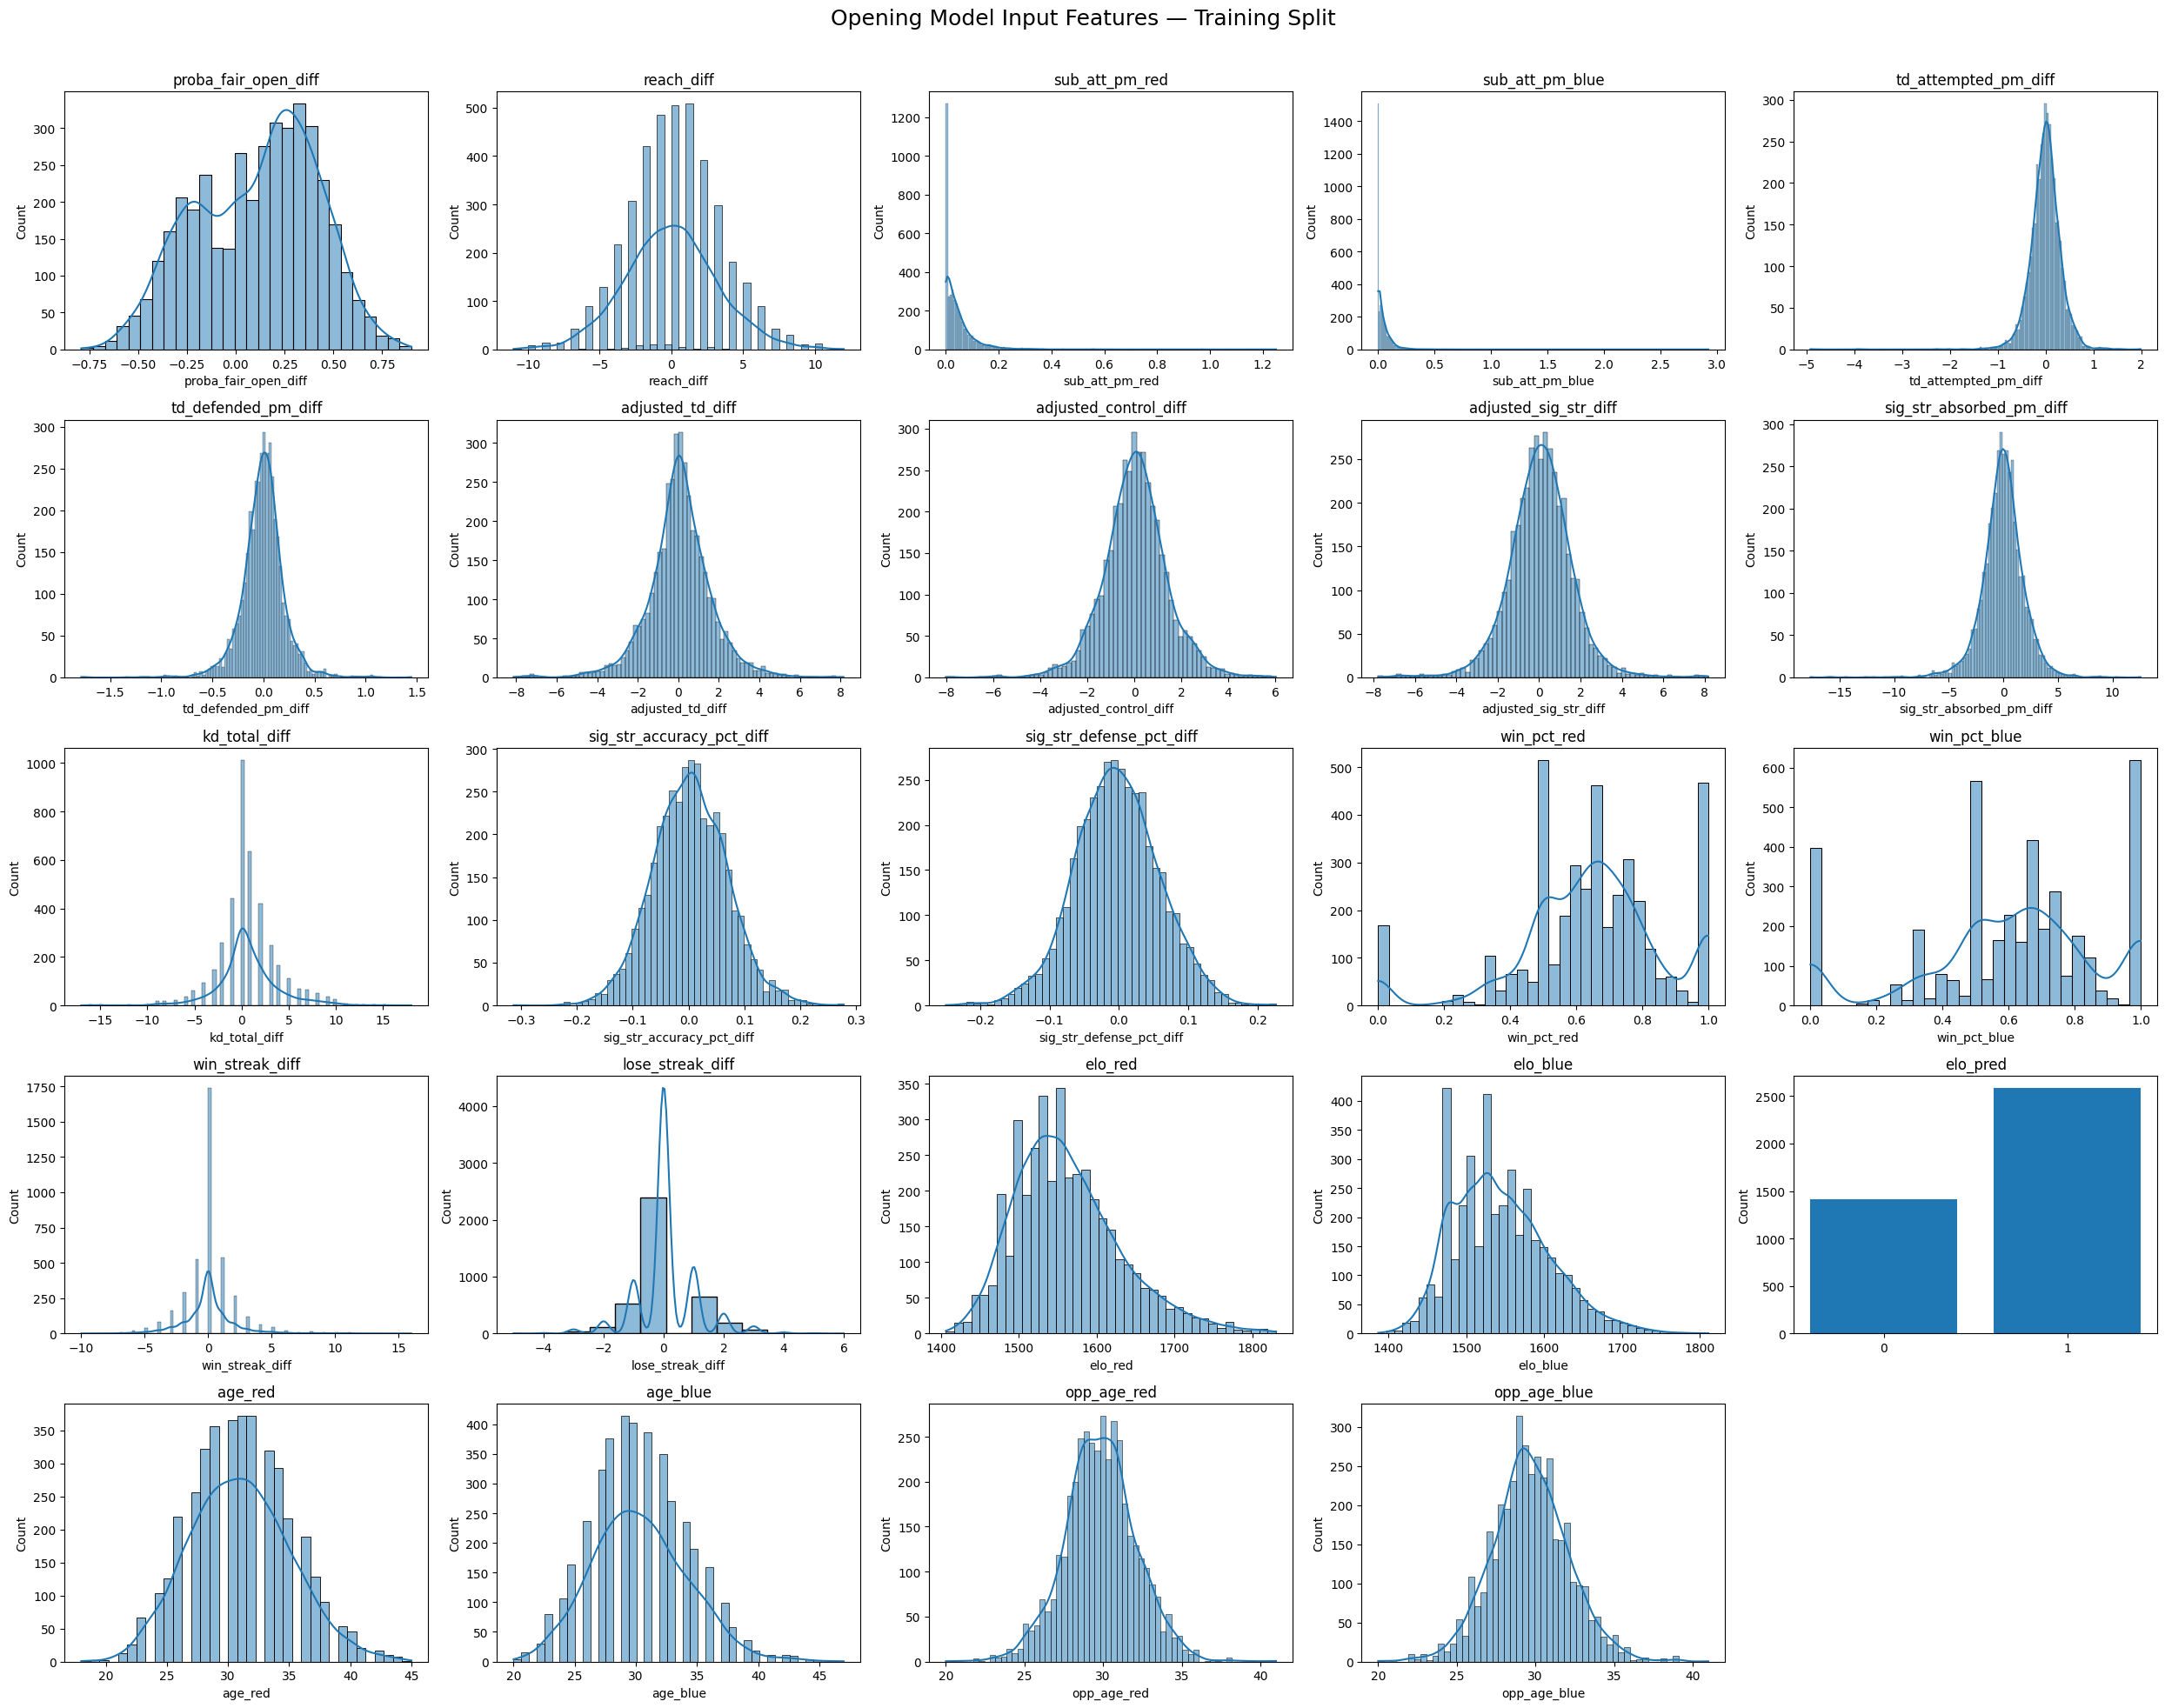

Saved: C:\Users\jcmar\my_files\SportsBetting\Data\plot_pngs\input_plots.png


In [4]:
feature_fig = plot_feature_distributions(train_df, save_path=plot_path)
print(f"Saved: {plot_path}")


In [ ]:
# Correlations also use only the configured opening features and training rows.
corr = X_train.apply(pd.to_numeric, errors="raise").corr()
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(corr, xticklabels=corr.columns, yticklabels=corr.columns,
            cmap="coolwarm", center=0, ax=ax)
ax.set_title("Opening Model Feature Correlations â€” Training Split")
fig.tight_layout()
plt.show()
